In [1]:
import sys
import os
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib.pyplot import rc_context
import matplotlib.pyplot as plt

In [2]:
sys.path.append(os.path.abspath('/home/huc/projects/scAuto/scAnnotation'))
sys.path.append(os.path.abspath('/home/huc/projects/scRNA_resources/markers'))

import scAnnotation_helpers as scAnnotation_helpers
import marker_helpers as marker_helpers


import importlib
importlib.reload(scAnnotation_helpers)
importlib.reload(marker_helpers)

/home/huc/.conda/envs/py312r43/lib/python3.12/site-packages/milopy/core.py:1: DeprecationWarning: 'audioop' is deprecated and slated for removal in Python 3.13
  from audioop import add


<module 'marker_helpers' from '/home/huc/projects/scRNA_resources/markers/marker_helpers.py'>

In [3]:
marker_yaml_file = "/home/huc/projects/scRNA_resources/markers/marker_collections/mouse_bone_marrow.yaml"

In [4]:
merge = sc.read_h5ad("/home/huc/projects/Ruoqiong_Cao.IAHSC/scRNA/3.annotation/processed_anndata/merged_integrated.h5ad")

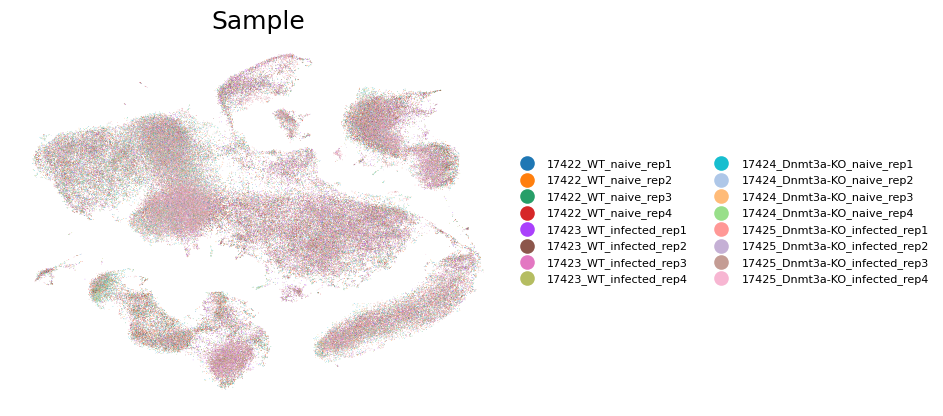

In [4]:
sc.pl.embedding(merge, 
    basis='X_umap', color=['sample'],
    add_outline=False, legend_loc='right margin',
    legend_fontsize=8, legend_fontoutline=2, frameon=False, ncols=1,
    title=['Sample'])

In [17]:
merge

AnnData object with n_obs × n_vars = 158292 × 2854
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'S_score', 'G2M_score', 'phase', 'ed_logprob', 'ed_fdr', 'ed_class', 'doublet_score', 'predicted_doublet', 'leiden', 'sample', 'leiden_uncorrected'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden', 'leiden_colors', 'leiden_uncorrected', 'leiden_uncorrected_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap', 'uncorrected'
    obsm: 'X_pca', 'X_pca_uncorrected', 'X_umap', 'X_umap_uncorrected'
    varm: 'PCs'
    obsp: 'connectivities', 'distances', 'uncorrected_connectivities', 'uncorrected_distances'

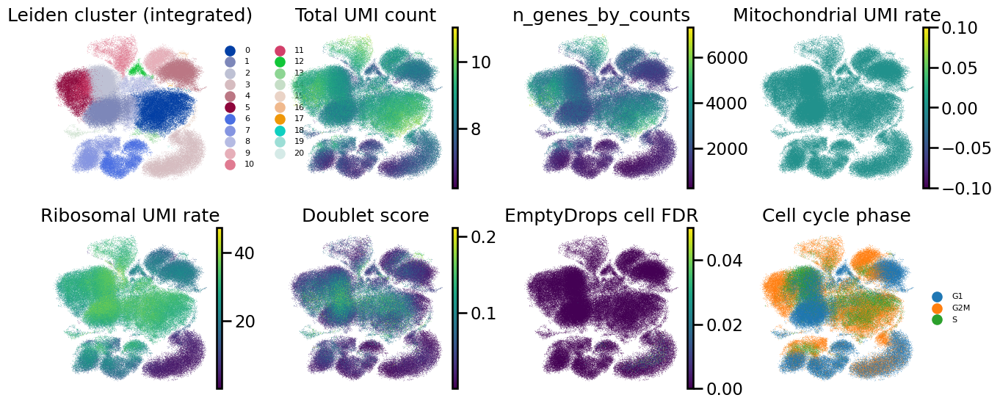

In [19]:
with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.embedding(merge, 
        basis='X_umap', color=['leiden', 'log1p_total_counts', "n_genes_by_counts", 'pct_counts_mt', 'pct_counts_ribo', 'doublet_score', 'ed_fdr', "phase"],
        add_outline=False, legend_loc='right margin',
        legend_fontsize=8, legend_fontoutline=2, frameon=False, ncols=4,
        title=['Leiden cluster (integrated)', 'Total UMI count', "n_genes_by_counts", 'Mitochondrial UMI rate', 'Ribosomal UMI rate', 'Doublet score', 'EmptyDrops cell FDR', "Cell cycle phase"])

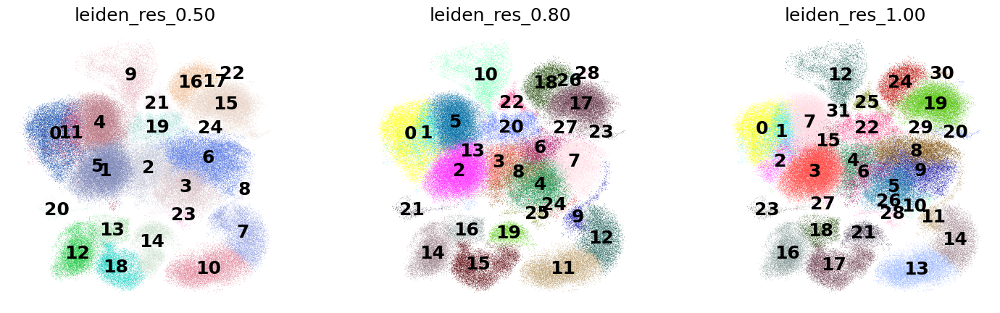

In [22]:
sc.pp.neighbors(merge, n_neighbors=10, n_pcs = 50)
for res in [0.1, 0.2, 0.3, 0.4, 0.5, 0.8, 1]:
    sc.tl.leiden(
        merge, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )

sc.tl.umap(merge, min_dist = 0.8, spread = 0.5)


with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(
        merge,
        color=["leiden_res_0.50", "leiden_res_0.80", "leiden_res_1.00"],
        legend_loc="on data",
        frameon=False,
        ncols=4,
    )

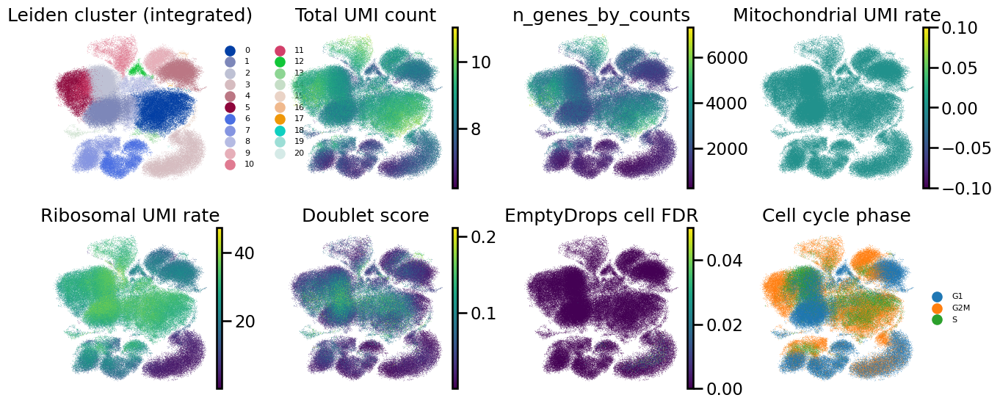

In [23]:
with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.embedding(merge, 
        basis='X_umap', color=['leiden', 'log1p_total_counts', "n_genes_by_counts", 'pct_counts_mt', 'pct_counts_ribo', 'doublet_score', 'ed_fdr', "phase"],
        add_outline=False, legend_loc='right margin',
        legend_fontsize=8, legend_fontoutline=2, frameon=False, ncols=4,
        title=['Leiden cluster (integrated)', 'Total UMI count', "n_genes_by_counts", 'Mitochondrial UMI rate', 'Ribosomal UMI rate', 'Doublet score', 'EmptyDrops cell FDR', "Cell cycle phase"])

## Explore the pre-defined markers

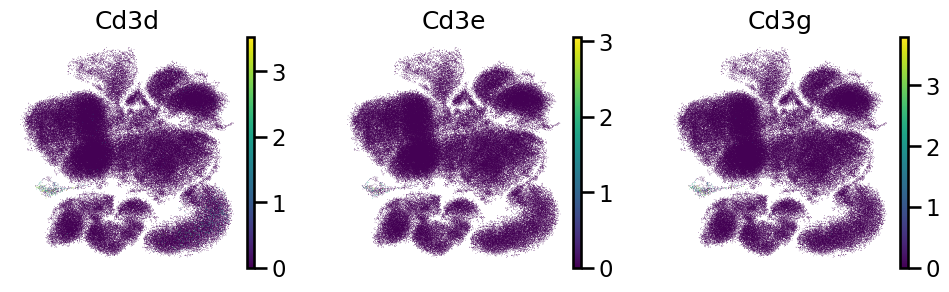

In [16]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "T")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

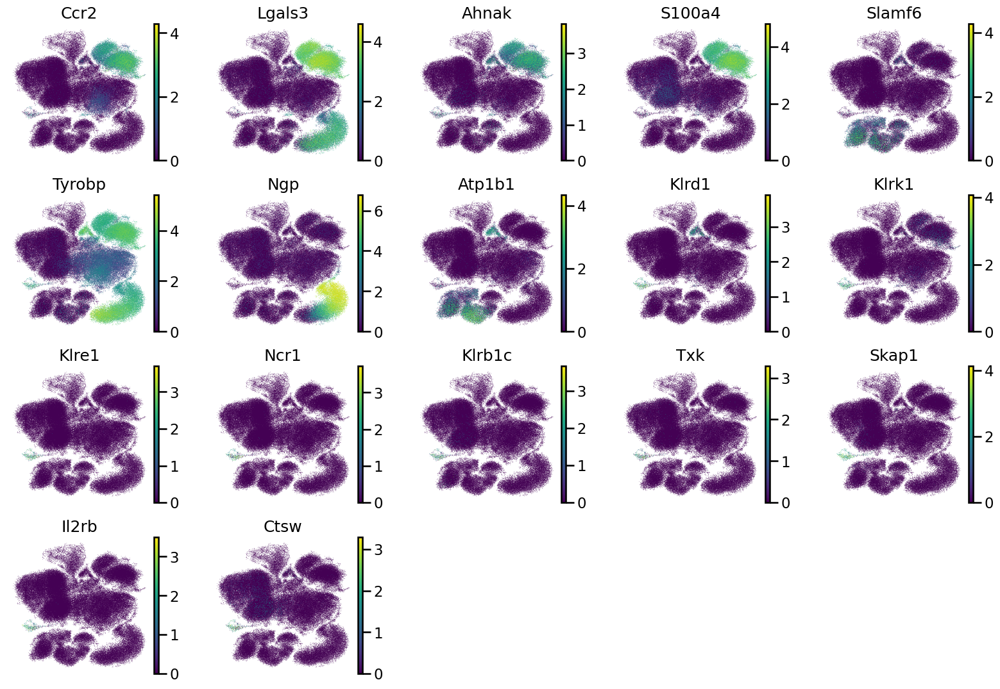

In [15]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Natural_killer")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

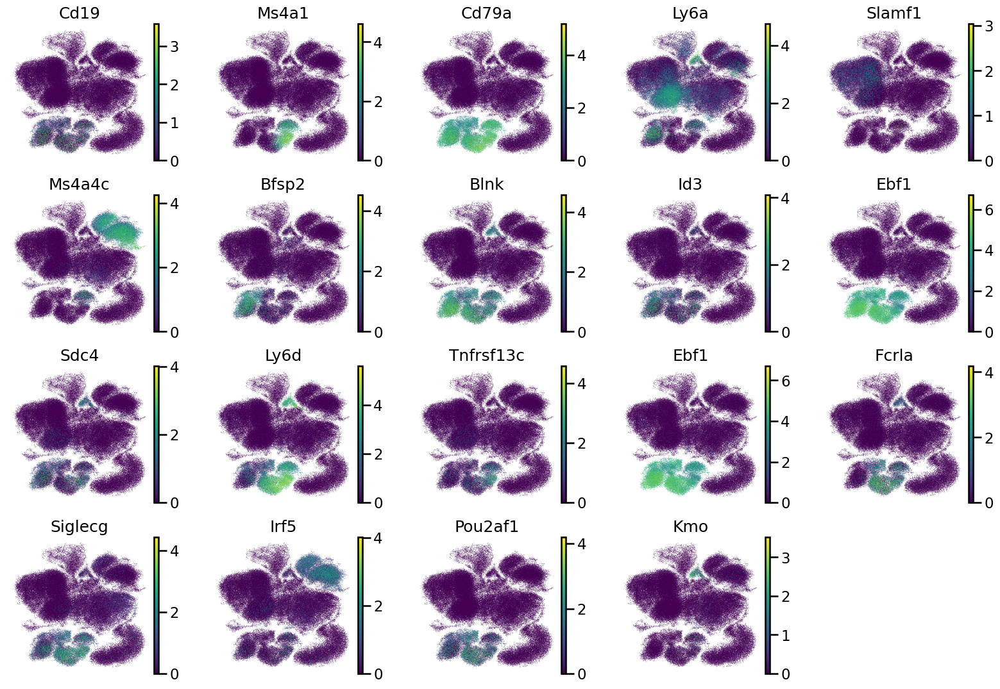

In [14]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "B")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

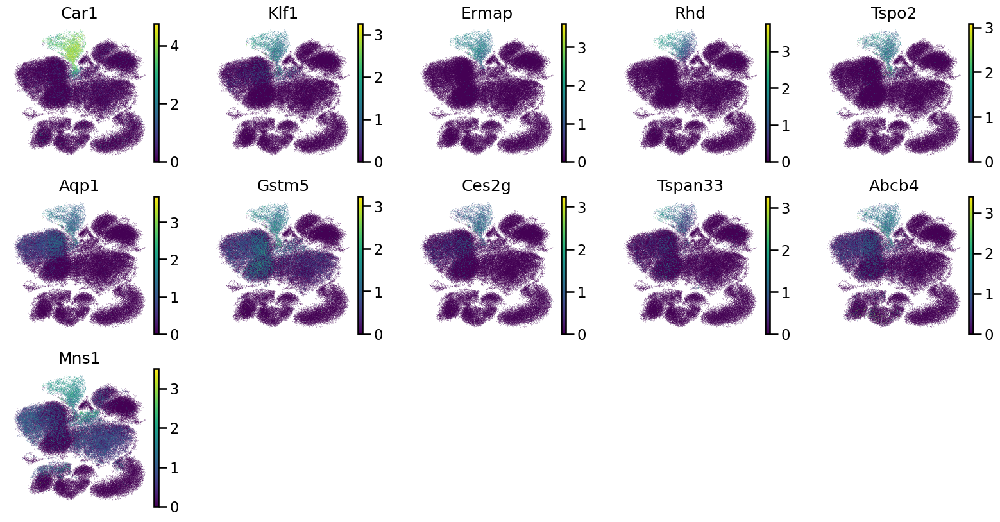

In [13]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Erythrocyte")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

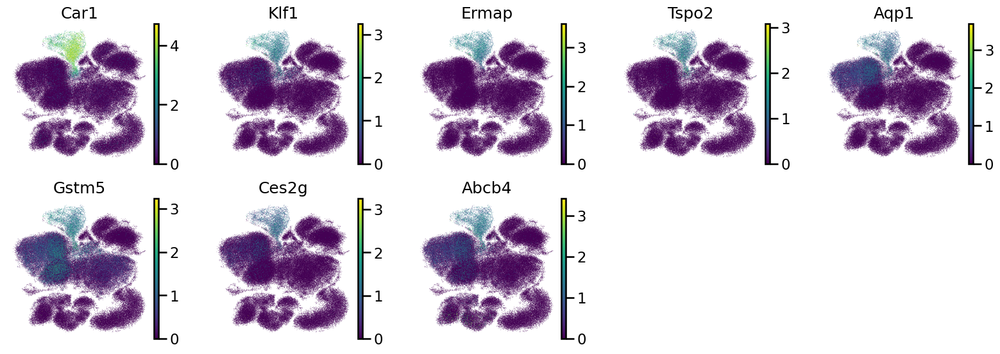

In [12]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MkE")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

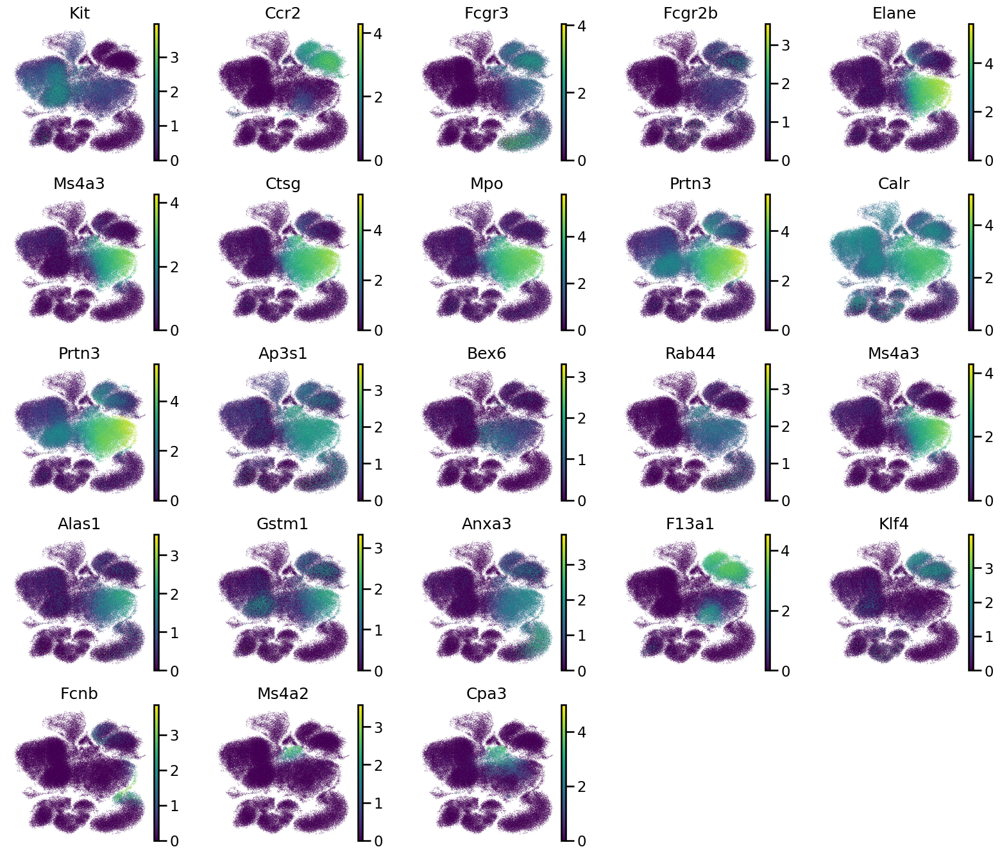

In [11]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "GMP")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

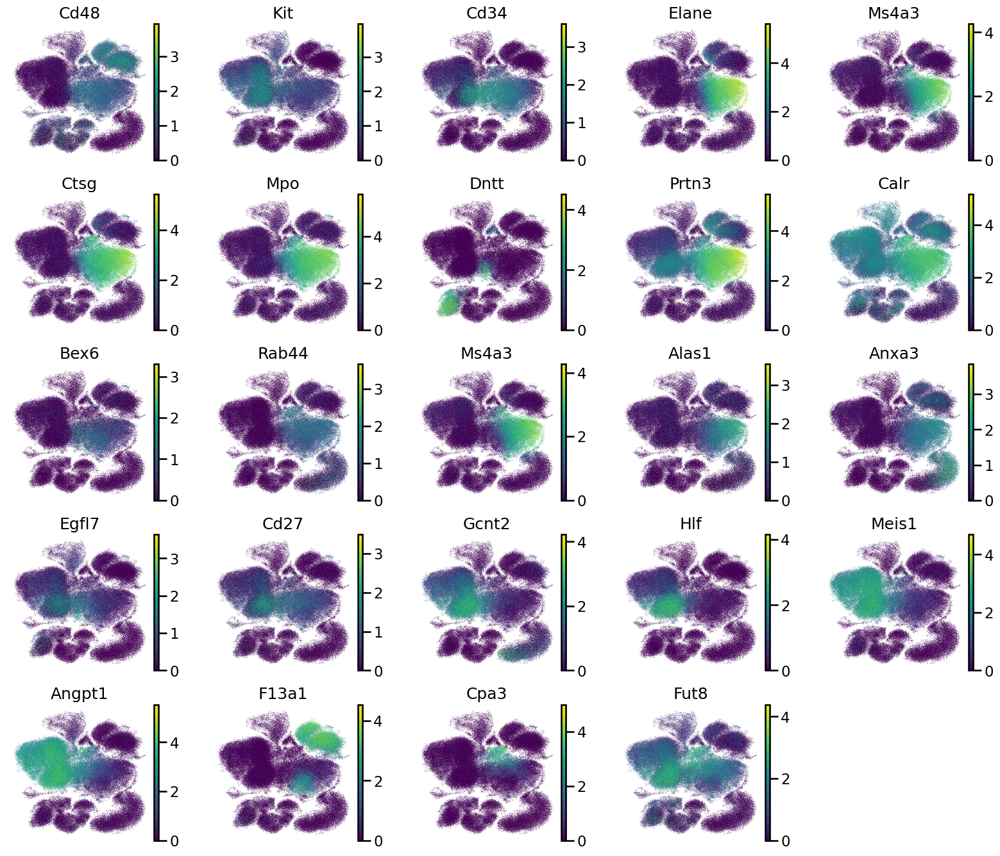

In [6]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MMP3")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

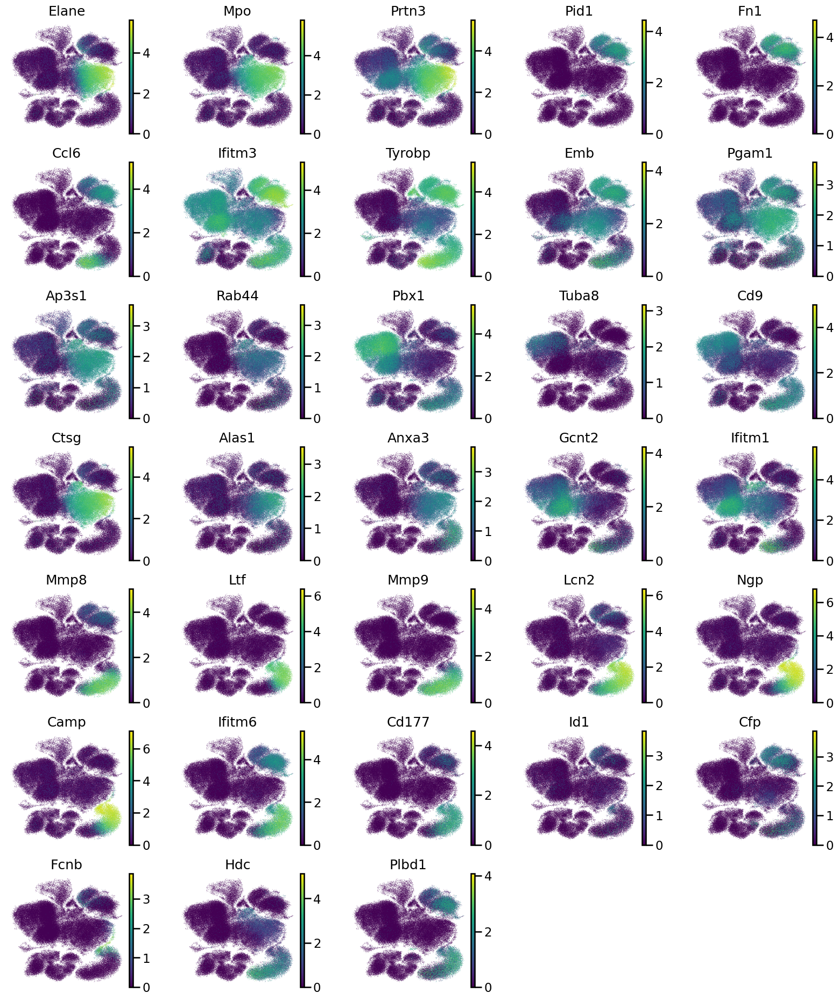

In [7]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Neutrophil")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

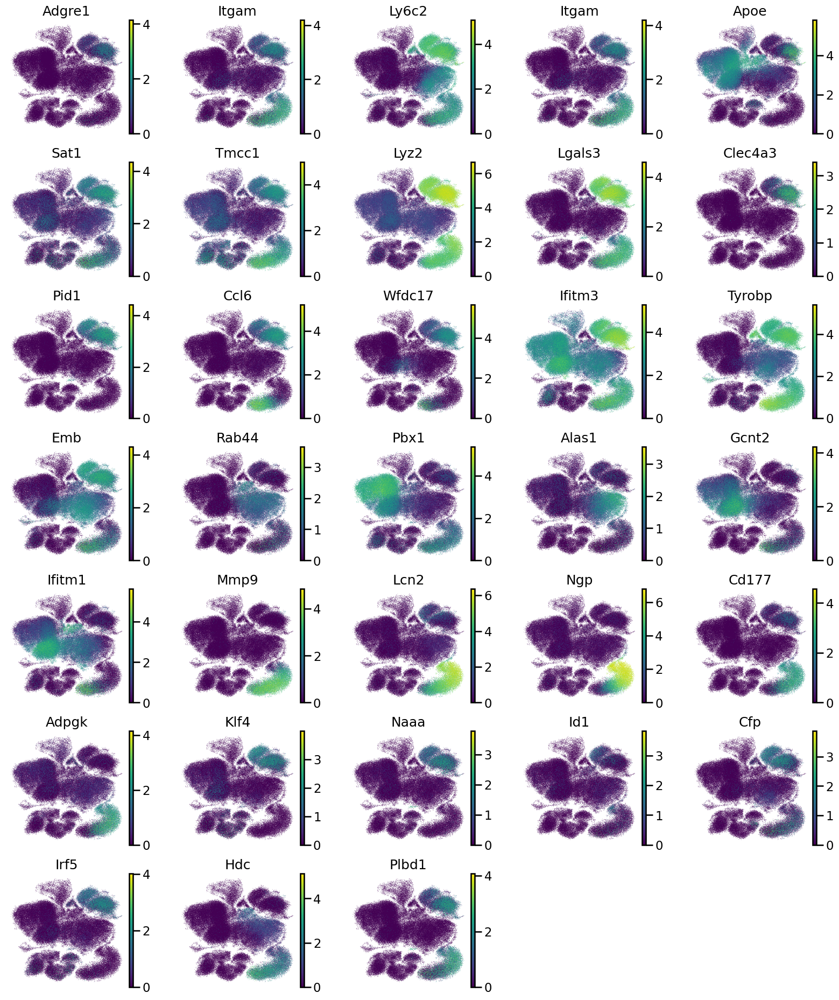

In [8]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "Macrophage")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

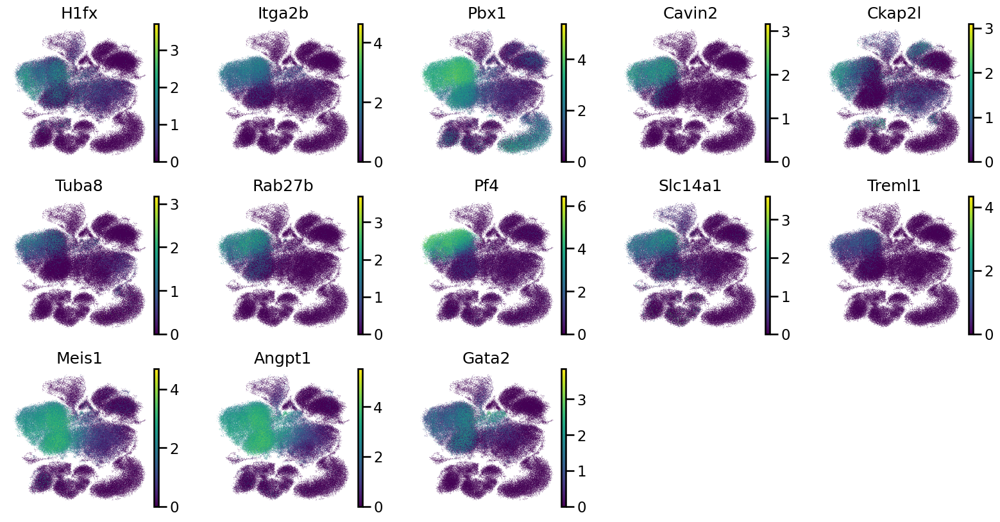

In [9]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "MkP")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

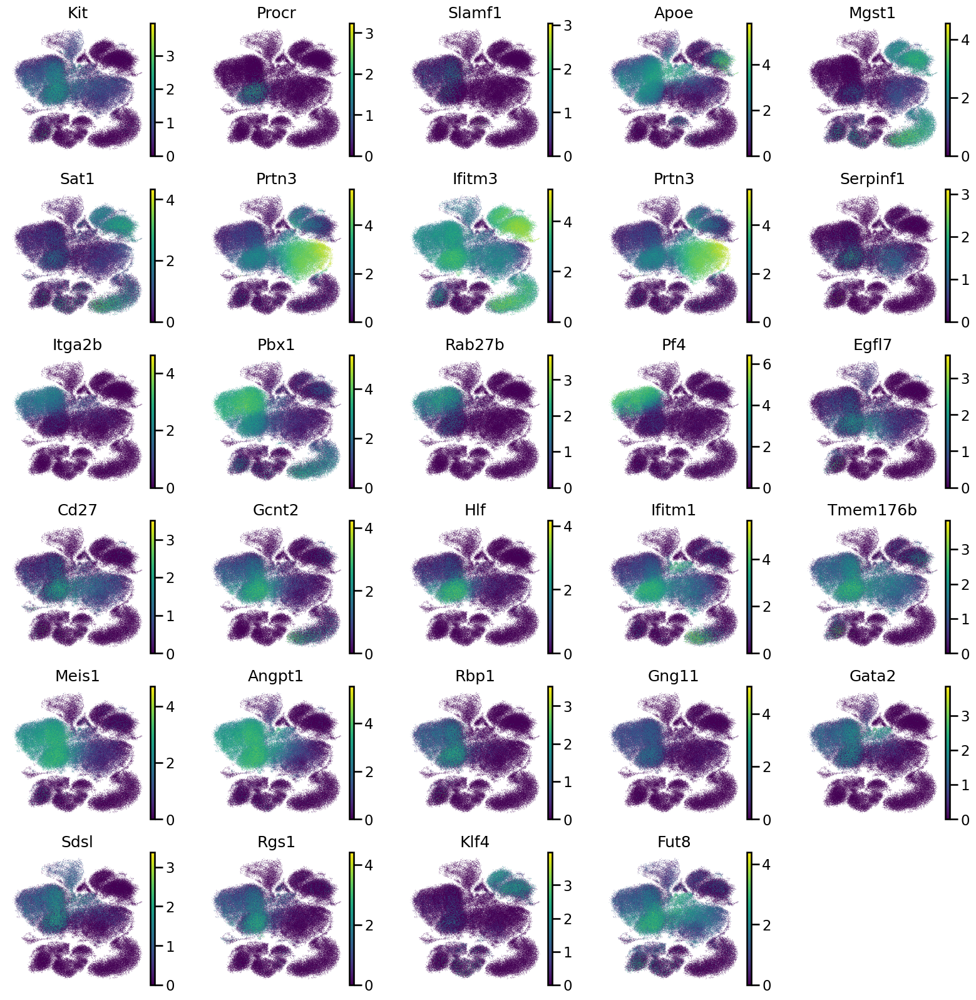

In [77]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "HSC")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        merge,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

### Set the annotations

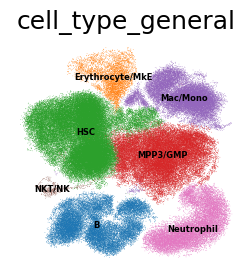

In [ ]:
# Set default value to "T"
merge.obs["cell_type_general"] = "Unassigned"

merge.obs.loc[merge.obs["leiden_res_0.50"].isin(["9"]), "cell_type_general"] = "Erythrocyte/MkE"
merge.obs.loc[merge.obs["leiden_res_0.50"].isin(["0", "11", "4", "5", "1", "19"]), "cell_type_general"] = "HSC"
merge.obs.loc[merge.obs["leiden_res_0.50"].isin(["12", "13", "14", "18"]), "cell_type_general"] = "B"
merge.obs.loc[merge.obs["leiden_res_0.50"].isin(["7", "10"]), "cell_type_general"] = "Neutrophil"
merge.obs.loc[merge.obs["leiden_res_0.50"].isin(["2", "3", "6", "8", "23"]), "cell_type_general"] = "MPP3/GMP"
merge.obs.loc[merge.obs["leiden_res_0.50"].isin(["21", "24", "15", "16", "17", "22"]), "cell_type_general"] = "Mac/Mono"
merge.obs.loc[merge.obs["leiden_res_0.50"].isin(["20"]), "cell_type_general"] = "NKT/NK"

with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(merge, color=["cell_type_general"],
        show=True, add_outline = False,
        legend_fontsize=6, frameon=False, title='cell_type_general', legend_loc="on data")

In [104]:
merge.write('/home/huc/projects/Ruoqiong_Cao.IAHSC/scRNA/3.annotation/processed_anndata/IAHSC.scRNA.annotation_general.April23.h5ad')

In [27]:
cell_counts_df = merge.obs['cell_type_general'].value_counts().reset_index()
cell_counts_df.columns = ['cell_type_general', 'cell_count']
print(cell_counts_df)

  cell_type_general  cell_count
0               HSC       58560
1          MPP3/GMP       33325
2          Mac/Mono       22309
3                 B       21303
4        Neutrophil       17216
5   Erythrocyte/MkE        5041
6            NKT/NK         538


# Subtyping for HSC

Subset Data dimension: 58560 cells x 26760 genes

Finished.

Normalizing data...

No. of HVG = 2550

Finished.

Dimension reduction and clustering...

2025-04-22 22:31:15,282 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-04-22 22:31:19,830 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-04-22 22:31:19,981 - harmonypy - INFO - Iteration 1 of 20
2025-04-22 22:31:34,794 - harmonypy - INFO - Iteration 2 of 20
2025-04-22 22:31:50,233 - harmonypy - INFO - Iteration 3 of 20
2025-04-22 22:32:04,944 - harmonypy - INFO - Iteration 4 of 20
2025-04-22 22:32:20,705 - harmonypy - INFO - Iteration 5 of 20
2025-04-22 22:32:34,824 - harmonypy - INFO - Iteration 6 of 20
2025-04-22 22:32:43,340 - harmonypy - INFO - Iteration 7 of 20
2025-04-22 22:32:50,381 - harmonypy - INFO - Iteration 8 of 20
2025-04-22 22:32:56,856 - harmonypy - INFO - Iteration 9 of 20
2025-04-22 22:33:03,277 - harmonypy - INFO - Iteration 10 of 20
2025-04-22 22:33:09,899 - harmonypy - INFO - Iteration 11 of 20
2025-04-22 22:33:16,344 - harmonypy - INFO - Iteration 12 of 20
2025-04-22 22:33:23,137 - harmonypy - INFO - Iteration 13 of

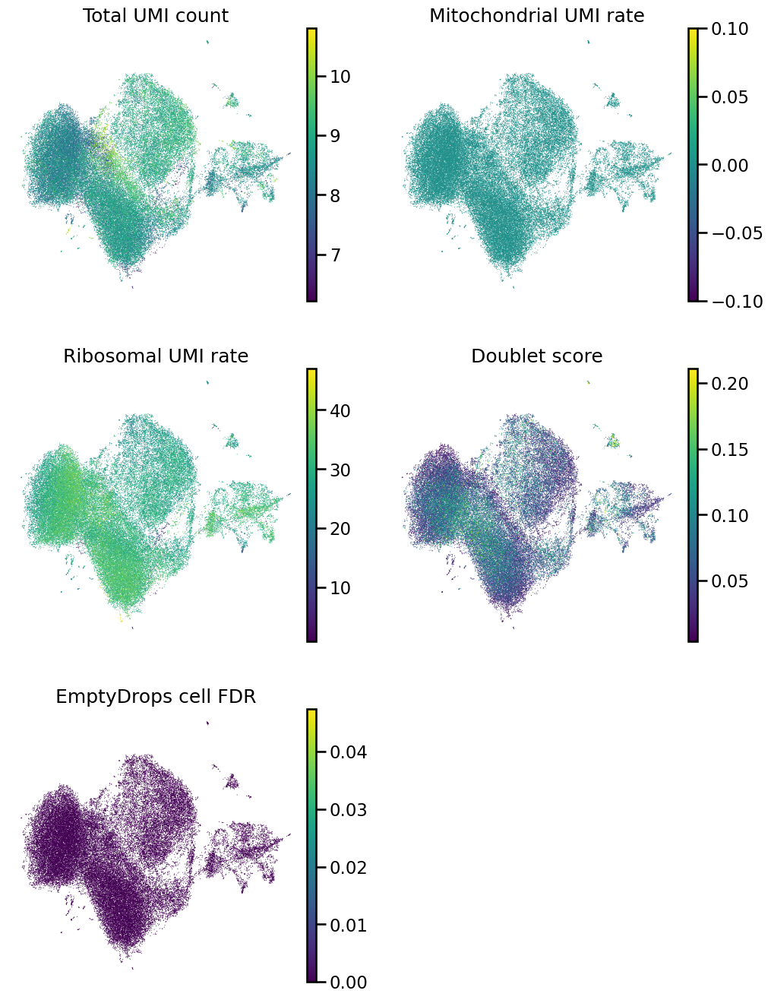

Finished.

In [26]:
adata_hsc = scAnnotation_helpers.subintegrate(
    merge, 
    cells_to_subset=merge.obs.query('cell_type_general == "HSC"').index, 
    variable_to_integrate='sample',
    regress_out='basic'
)

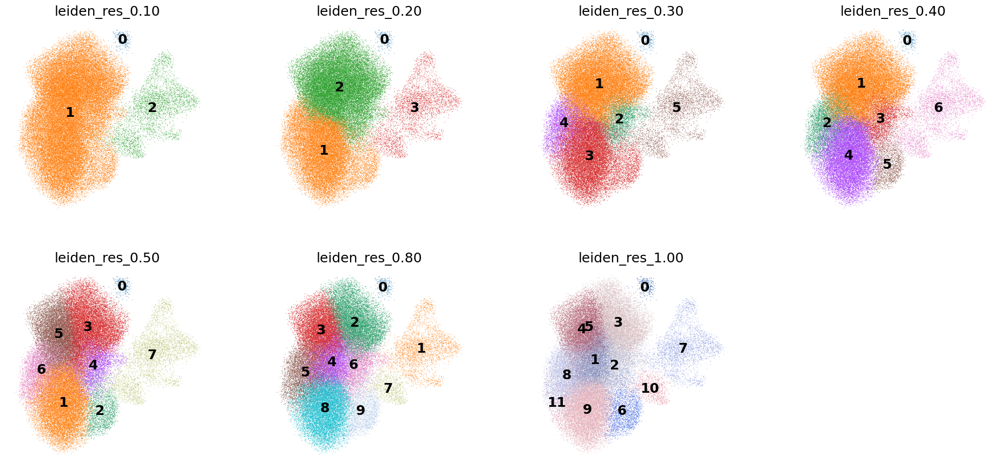

In [78]:
sc.pp.neighbors(adata_hsc, n_neighbors=50, n_pcs =50)
for res in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]:
    sc.tl.leiden(
        adata_hsc, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )

sc.tl.umap(adata_hsc, min_dist = 0.8, spread = 0.5)


with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(
        adata_hsc,
        color=["leiden_res_0.10", "leiden_res_0.20", "leiden_res_0.30", "leiden_res_0.40", "leiden_res_0.50", "leiden_res_0.80", "leiden_res_1.00"],
        legend_loc="on data",
        frameon=False,
        ncols=4,
    )

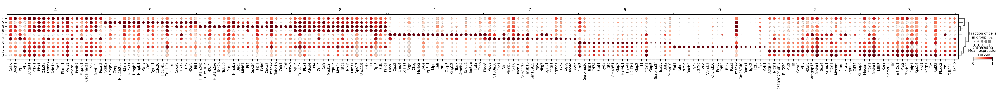

In [85]:
sc.tl.rank_genes_groups(adata_hsc, groupby="leiden_res_0.80", method="wilcoxon")

sc.pl.rank_genes_groups_dotplot(
    adata_hsc, groupby="leiden_res_0.80", standard_scale="var", n_genes=20
)

###  LT-HSC: Sca1 (Ly6a)-, cKit(Kit)+, Slamf1+, CD48-, CD34-

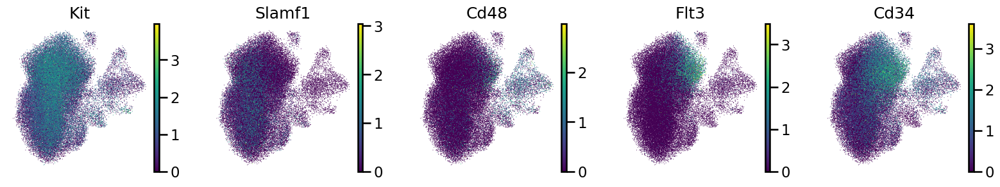

In [79]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "LT-HSC")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata_hsc,
        color=specific_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

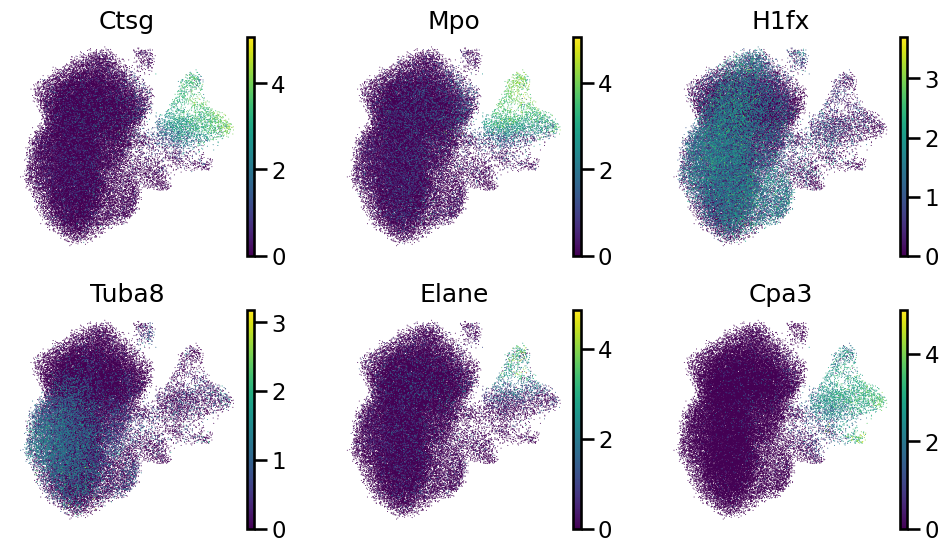

In [81]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "ST-HSC")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata_hsc,
        color=specific_markers, 
        legend_loc="on data", frameon=False, ncols=3,
    )

### IA-HSC: Sca1 (Ly6a)-, cKit(Kit)+, Cd81+, Cd24a+, Cd9+

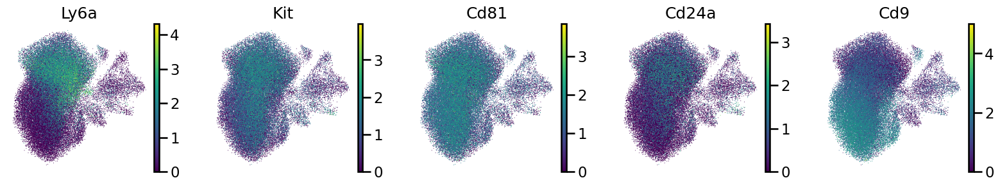

In [75]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "IA-HSC")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata_hsc,
        color=specific_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

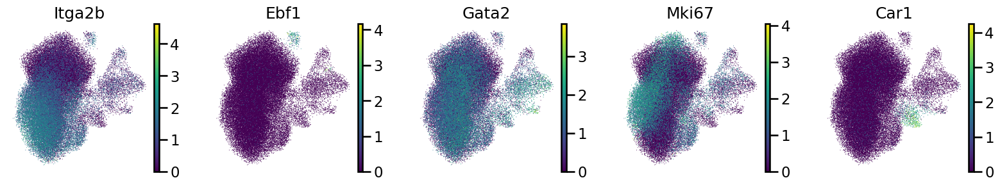

In [88]:
with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata_hsc,
        color=['Itga2b', "Ebf1", "Gata2", "Mki67", "Car1"], 
        frameon=False, ncols=5,
    )

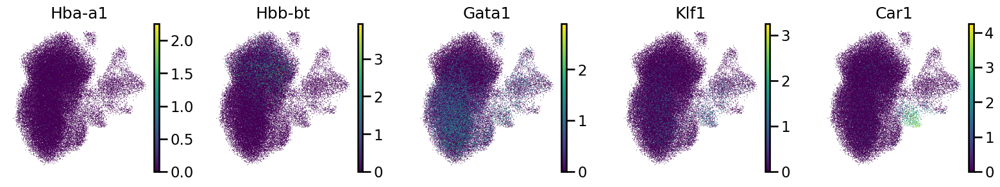

In [91]:
with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata_hsc,
        color=['Hba-a1', "Hbb-bt", "Gata1", "Klf1", "Car1"], 
        frameon=False, ncols=5,
    )

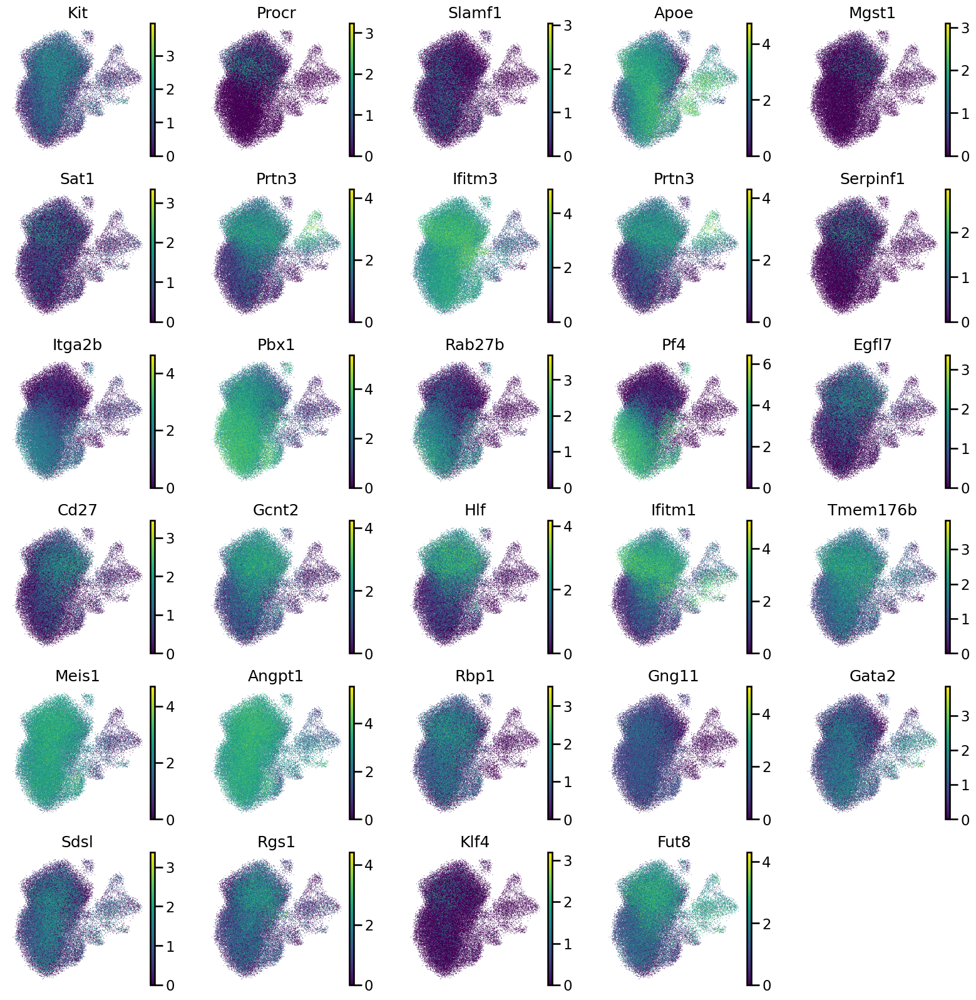

In [82]:
specific_markers, all_markers = marker_helpers.get_markers_for_cell_type(marker_yaml_file, "HSC")

with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata_hsc,
        color=all_markers, 
        legend_loc="on data", frameon=False, ncols=5,
    )

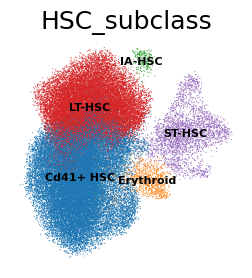

In [97]:
# Set default value to "T"
adata_hsc.obs["HSC_subclass"] = "Unassigned"

adata_hsc.obs.loc[adata_hsc.obs["leiden_res_0.80"].isin(["1"]), "HSC_subclass"] = "ST-HSC"
adata_hsc.obs.loc[adata_hsc.obs["leiden_res_0.80"].isin(["0"]), "HSC_subclass"] = "IA-HSC"
adata_hsc.obs.loc[adata_hsc.obs["leiden_res_0.80"].isin(["4", "5", "6", "8", "9"]), "HSC_subclass"] = "Cd41+ HSC"
adata_hsc.obs.loc[adata_hsc.obs["leiden_res_0.80"].isin(["7"]), "HSC_subclass"] = "Erythroid"
adata_hsc.obs.loc[adata_hsc.obs["leiden_res_0.80"].isin(["2", "3"]), "HSC_subclass"] = "LT-HSC"

with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(adata_hsc, color=["HSC_subclass"],
        show=True, add_outline = False,
        legend_fontsize=8, frameon=False, title='HSC_subclass', legend_loc="on data")

Cell type: Cd41+ HSC


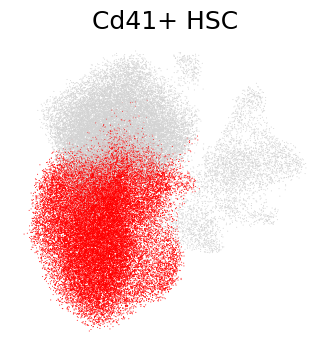

Cell type: Erythroid


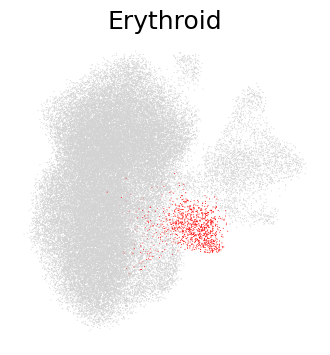

Cell type: IA-HSC


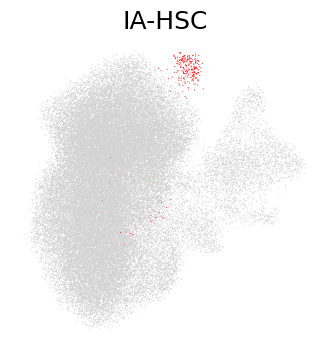

Cell type: LT-HSC


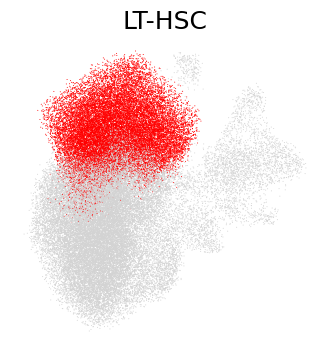

Cell type: ST-HSC


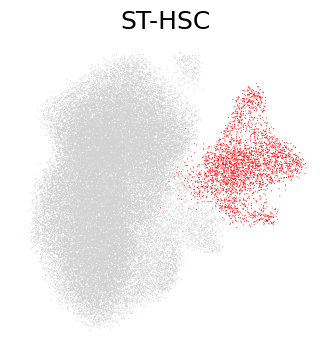

In [100]:
# Assume `adata` is your AnnData object and 'cell_type' is the column with cell labels
for cell_type_of_interest in adata_hsc.obs['HSC_subclass'].cat.categories:
    print(f"Cell type: {cell_type_of_interest}")
    # cell_type_of_interest = "inhibitory_neuron"  # Replace with your cell type

    # Create a color palette where the cell type of interest is colored, others grey
    palette = {
        cell_type: "red" if cell_type == cell_type_of_interest else "lightgrey"
        for cell_type in adata_hsc.obs['HSC_subclass'].cat.categories
    }

    # Plot UMAP with custom palette
    with rc_context({"figure.figsize": (4, 4)}):
        sc.pl.umap(
            adata_hsc,
            color='HSC_subclass',
            palette=palette,
            title=f"{cell_type_of_interest}",
            legend_loc='none',  # or 'right margin'
            frameon=False, show=True,
            legend_fontsize=8  # Adjust point size as needed
        )
    # plt.savefig("./plots/cell_type_highlighted_" + cell_type_of_interest + ".png")


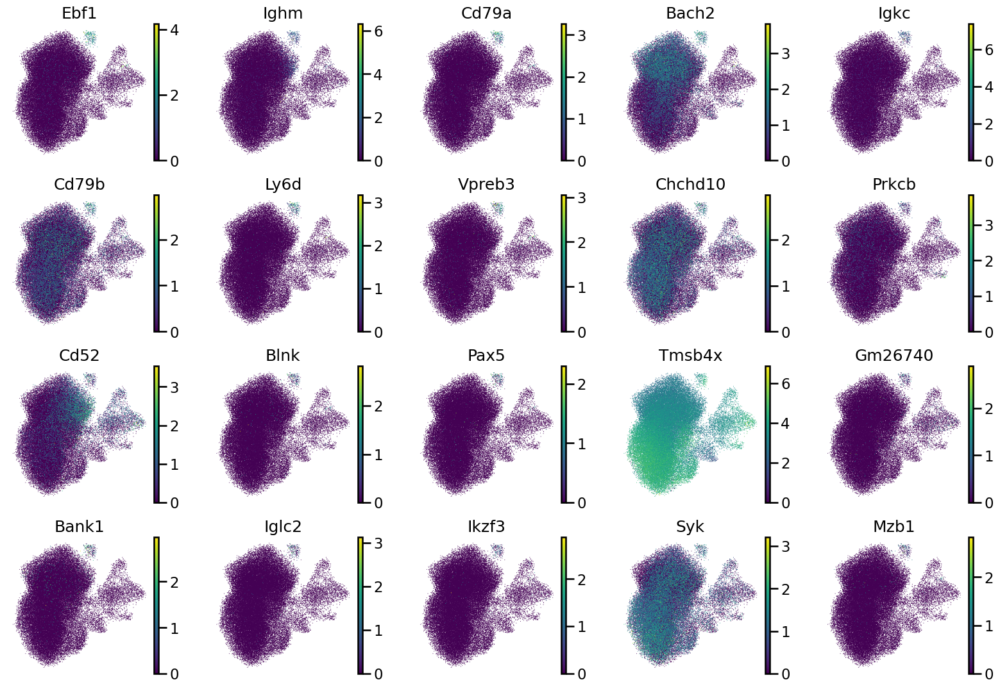

In [102]:
with plt.rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(
        adata_hsc,
        color=sc.get.rank_genes_groups_df(adata_hsc, group="0").head(20)['names'].values.tolist(),
        legend_loc="on data", frameon=False, ncols=5,
    )

In [103]:
cell_counts_df = adata_hsc.obs['HSC_subclass'].value_counts().reset_index()
cell_counts_df.columns = ['HSC_subclass', 'cell_count']
print(cell_counts_df)

  HSC_subclass  cell_count
0    Cd41+ HSC       31946
1       LT-HSC       22365
2       ST-HSC        2976
3    Erythroid         997
4       IA-HSC         276


In [105]:
adata_hsc.write('/home/huc/projects/Ruoqiong_Cao.IAHSC/scRNA/3.annotation/processed_anndata/IAHSC.scRNA.hsc_subclasses.April23.h5ad')

# Integration annotations

In [62]:
adata_all = sc.read_h5ad('/home/huc/projects/Ruoqiong_Cao.IAHSC/scRNA/3.annotation/processed_anndata/IAHSC.scRNA.annotation_general.April23.h5ad')
adata_hsc = sc.read_h5ad('/home/huc/projects/Ruoqiong_Cao.IAHSC/scRNA/3.annotation/processed_anndata/IAHSC.scRNA.hsc_subclasses.April23.h5ad')

In [7]:
adata_all
# merge_hsc

AnnData object with n_obs × n_vars = 158292 × 2854
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'S_score', 'G2M_score', 'phase', 'ed_logprob', 'ed_fdr', 'ed_class', 'doublet_score', 'predicted_doublet', 'leiden', 'sample', 'leiden_uncorrected', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.80', 'leiden_res_1.00', 'cell_type_general'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cell_type_general_colors', 'hvg', 'leiden', 'leiden_colors', 'leiden_res_0.10', 'leiden_res_0.20', 'leiden_res_0.30', 'leiden_res_0.40', 'leiden_res_0.50', 'leiden_res_0.50_colors', 'leiden_res_

In [63]:
combined_categories = adata_all.obs["cell_type_general"].cat.categories.union(adata_hsc.obs["HSC_subclass"].cat.categories)
adata_all.obs["Cell_types_fine"] = adata_all.obs["cell_type_general"].astype("category")
adata_all.obs["Cell_types_fine"] = adata_all.obs["Cell_types_fine"].cat.set_categories(combined_categories)
adata_hsc.obs["HSC_subclass"] = adata_hsc.obs["HSC_subclass"].cat.set_categories(combined_categories)
adata_all.obs.loc[adata_hsc.obs.index, "Cell_types_fine"] = adata_hsc.obs["HSC_subclass"]
adata_all.obs["Cell_types_fine_finalized"] = adata_all.obs["Cell_types_fine"].replace("Erythroid", "Erythrocyte/MkE")

In [68]:
adata_all.obs["Cell_types_major_finalized"] = adata_all.obs["cell_type_general"].astype("category")
adata_all.obs.loc[adata_hsc.obs.query('HSC_subclass.isin(["Erythroid"])').index, "Cell_types_major_finalized"] = 'Erythrocyte/MkE'

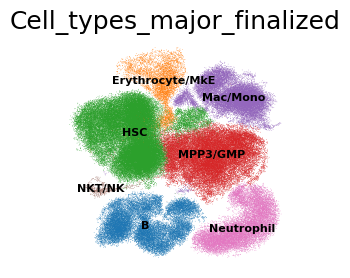

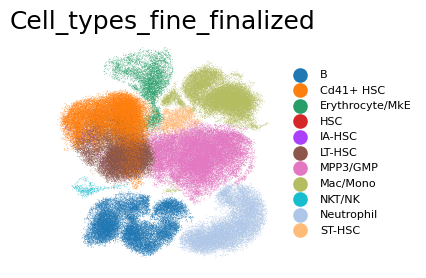

In [69]:
with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(adata_all, color=["Cell_types_major_finalized"],
        show=True, add_outline = False,
        legend_fontsize=8, frameon=False, title='Cell_types_major_finalized', legend_loc="on data")


with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.umap(adata_all, color=["Cell_types_fine_finalized"],
        show=True, add_outline = False,
        legend_fontsize=8, frameon=False, title='Cell_types_fine_finalized', legend_loc="right margin")

In [70]:
adata_all.write_h5ad('/home/huc/projects/Ruoqiong_Cao.IAHSC/scRNA/3.annotation/processed_anndata/IAHSC.scRNA.annotation_finalized.June16.h5ad')